# 01 · Entendimiento y preparación de los datos

**Taller 2 – MINE-4101 Ciencia de Datos Aplicada (2026-20)**
Caso: FinAlpes – prueba de concepto de una herramienta de predicción de abandono (*churn*) de clientes bancarios.

Este notebook cubre el **Entendimiento de los datos**:

1. Estructura del dataset: dimensiones y tipos de variables.
2. Distribución de las variables continuas, categóricas, binarias y de la variable objetivo.
3. Revisión de calidad: unicidad, completitud, consistencia y validez.
4. Tratamiento: duplicados, valores inválidos, inconsistencias y valores atípicos.
5. Relación de cada variable con el abandono (gráficos y pruebas estadísticas) y selección de variables.

**Salida:** `data/processed/churn_clean.csv`, que usa el notebook `02_modelado_interpretacion.ipynb`.

> La imputación definitiva de nulos **no** se hace aquí. Se hace dentro del *pipeline* del modelo, con valores calculados solo sobre el conjunto de entrenamiento, para evitar fuga de datos.

In [ ]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 50)

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold", "font.size": 10,
})
C_NO, C_SI = "#2a78d6", "#eb6834"
C_LR, C_DT = "#2a78d6", "#eb6834"
C_GRIS = "#8a8984"
PAL_CHURN = {0: C_NO, 1: C_SI}

DATA_DIR = Path("../data")
PROC_DIR = DATA_DIR / "processed"
FIG_DIR = Path("../reports/figures")
for d in (PROC_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
SEED = 42

from scipy import stats
import matplotlib.ticker as mticker

## 1. Carga y estructura del dataset

**Diccionario de datos** (fuente: [Prácticas de Machine Learning – Uniandes](https://datascience-uniandes.github.io/PracticasMachineLearning/datos/churn/)):

| Variable | Descripción | Tipo | Rango válido |
|---|---|---|---|
| `credit_score` | Puntaje crediticio | Continua | 300 – 850 |
| `country` | País de residencia | Categórica | France, Germany, Spain |
| `gender` | Género | Categórica | Female, Male |
| `age` | Edad (años) | Continua | 18 – 100 |
| `tenure` | Años como cliente | Discreta | 0 – 10 |
| `balance` | Saldo de la cuenta | Continua | ≥ 0 |
| `products_number` | Número de productos con el banco | Discreta | 1 – 4 |
| `credit_card` | Tiene tarjeta de crédito | Binaria | 0 / 1 |
| `active_member` | Es miembro activo | Binaria | 0 / 1 |
| `estimated_salary` | Salario estimado | Continua | ≥ 0 |
| `churn` | Abandonó el banco (**variable objetivo**) | Binaria | 0 / 1 |

In [2]:
df_raw = pd.read_csv(DATA_DIR / "churn.csv")
print(f"Dimensiones: {df_raw.shape[0]:,} registros x {df_raw.shape[1]} columnas")
df_raw.head()

Dimensiones: 10,045 registros x 11 columnas


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,418.0000,France,Female,46.0000,9,0.0000,1,1,1,"81,014.5000",1
1,689.0000,Germany,Male,67.0000,9,"157,094.7800",1,1,1,"99,490.0100",0
2,477.0000,Spain,Female,48.0000,2,"129,120.6400",1,0,1,"26,475.7900",0
3,573.0000,Germany,Female,35.0000,9,"206,868.7800",2,0,1,"102,986.1500",0
4,849.0000,France,Male,69.0000,7,"71,996.0900",1,1,1,"139,065.9400",0


In [3]:
CONTINUAS = ["credit_score", "age", "balance", "estimated_salary"]
DISCRETAS = ["tenure", "products_number"]
CATEGORICAS = ["country", "gender"]
BINARIAS = ["credit_card", "active_member"]
OBJETIVO = "churn"

tipos = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "tipo_analitico": [
        "continua" if c in CONTINUAS else "discreta" if c in DISCRETAS else
        "categórica" if c in CATEGORICAS else "binaria" if c in BINARIAS else "objetivo (binaria)"
        for c in df_raw.columns],
    "valores_unicos": df_raw.nunique(),
    "nulos": df_raw.isna().sum(),
})
tipos

,dtype,tipo_analitico,valores_unicos,nulos
credit_score,float64,continua,461,250
country,str,categórica,9,0
gender,str,categórica,4,0
age,float64,continua,76,300
tenure,int64,discreta,14,0
balance,float64,continua,6240,200
products_number,int64,discreta,4,0
credit_card,int64,binaria,2,0
active_member,int64,binaria,2,0
estimated_salary,float64,continua,9649,350


In [4]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
credit_score,"9,795.0000",650.6901,97.0880,95.0000,584.0000,652.0000,718.0000,"1,200.0000"
age,"9,745.0000",38.9376,10.7342,-1.0000,32.0000,37.0000,44.0000,210.0000
tenure,"10,045.0000",5.0189,2.9016,-2.0000,3.0000,5.0000,8.0000,25.0000
balance,"9,845.0000","76,317.5003","62,422.4348",0.0000,0.0000,"97,042.6000","127,559.9700","250,898.0900"
products_number,"10,045.0000",1.5301,0.5818,1.0000,1.0000,1.0000,2.0000,4.0000
credit_card,"10,045.0000",0.7045,0.4563,0.0000,0.0000,1.0000,1.0000,1.0000
active_member,"10,045.0000",0.5147,0.4998,0.0000,0.0000,1.0000,1.0000,1.0000
estimated_salary,"9,695.0000","100,069.0148","57,510.6891","-5,000.0000","51,013.6550","100,130.9500","149,382.8750","199,992.4800"
churn,"10,045.0000",0.2036,0.4027,0.0000,0.0000,0.0000,0.0000,1.0000


**Lectura inicial.** El archivo tiene 10.045 registros y 11 columnas: 4 continuas, 2 discretas, 2 categóricas, 2 binarias y la variable objetivo. `describe()` ya muestra problemas de calidad: `age` llega a 210, `credit_score` a 1.200, `tenure` a 25, `estimated_salary` tiene mínimos negativos y hay columnas con menos de 10.045 valores no nulos. La sección 3 los cuantifica.

## 2. Distribuciones
### 2.1 Variables continuas y discretas (datos crudos)

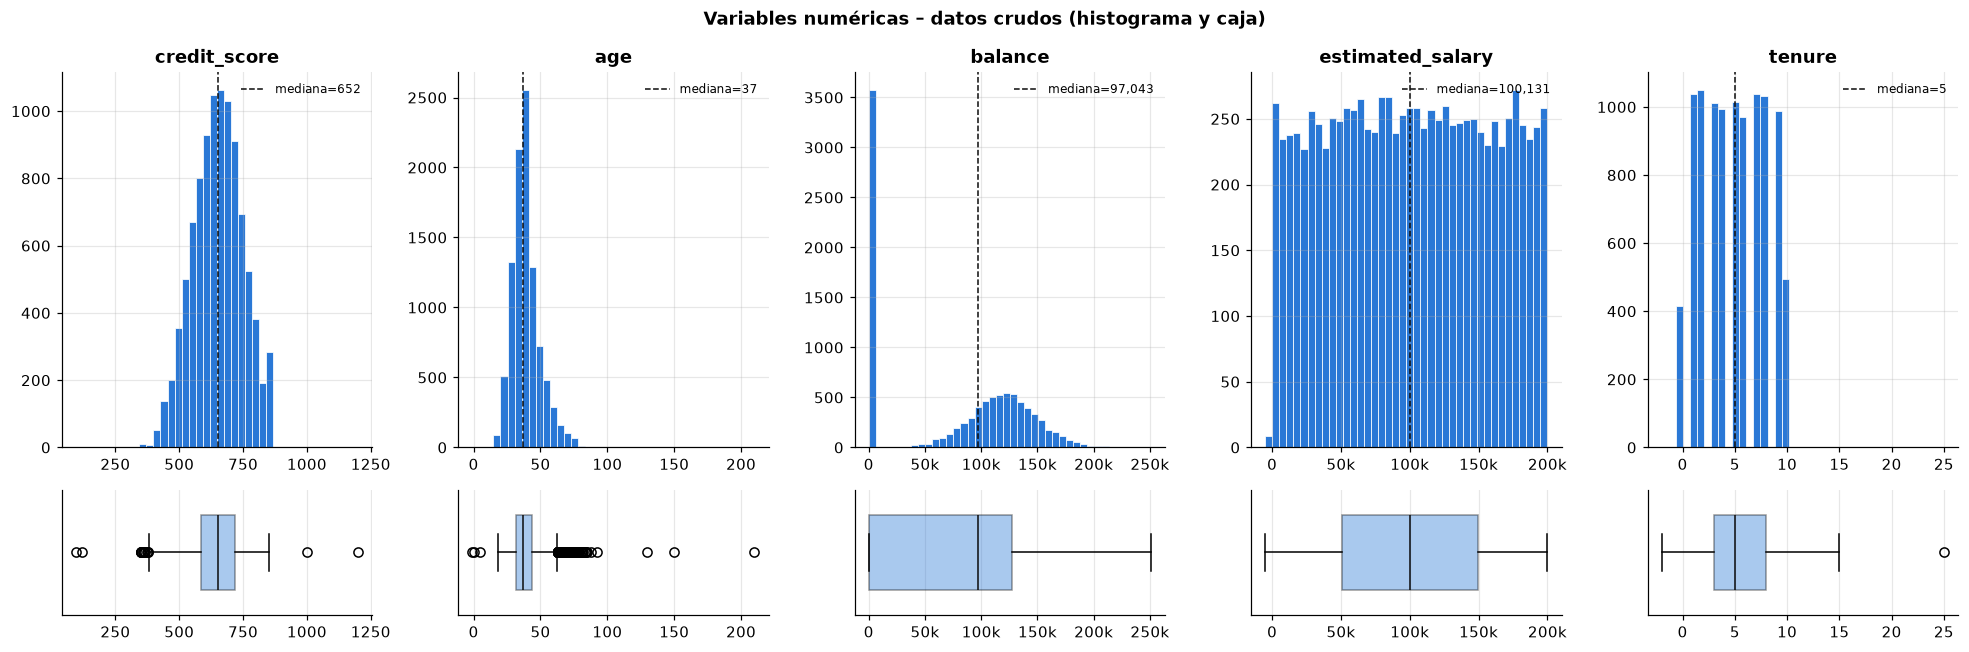

,asimetría,curtosis,% en el valor más frecuente
credit_score,-0.0791,-0.1705,2.3277
age,1.4942,9.2830,4.7512
balance,-0.1370,-1.4928,36.3027
estimated_salary,0.0040,-1.1812,0.0206
tenure,0.0418,-0.9471,10.4530


In [5]:
num_cols = CONTINUAS + ["tenure"]
fig, axes = plt.subplots(2, len(num_cols), figsize=(18, 6), gridspec_kw={"height_ratios": [3, 1]})
for i, c in enumerate(num_cols):
    s = df_raw[c].dropna()
    axes[0, i].hist(s, bins=40, color=C_NO, edgecolor="white", linewidth=0.5)
    axes[0, i].set_title(c)
    axes[0, i].axvline(s.median(), color="#0b0b0b", ls="--", lw=1, label=f"mediana={s.median():,.0f}")
    axes[0, i].legend(fontsize=8, frameon=False)
    axes[1, i].boxplot(s, vert=False, widths=0.6, patch_artist=True,
                       boxprops=dict(facecolor=C_NO, alpha=0.4), medianprops=dict(color="#0b0b0b"))
    axes[1, i].set_yticks([])
    for ax_ in axes[:, i]:
        ax_.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}k" if abs(x) >= 10000 else f"{x:.0f}"))
fig.suptitle("Variables numéricas – datos crudos (histograma y caja)", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_distribuciones_crudas.png", bbox_inches="tight"); plt.show()

pd.DataFrame({"asimetría": df_raw[num_cols].skew(), "curtosis": df_raw[num_cols].kurt(),
              "% en el valor más frecuente": [df_raw[c].value_counts(normalize=True).iloc[0] * 100 for c in num_cols]})

**Observaciones**

- `age` tiene sesgo positivo: la mayoría de los clientes tiene entre 30 y 45 años, con una cola larga hacia edades altas. Los valores extremos (130, 150, 210) son imposibles y deforman la escala.
- `balance` concentra **cerca del 36 % de los registros en 0** (clientes sin saldo). Fuera de ese pico, la distribución es aproximadamente normal alrededor de 120.000.
- `credit_score` es casi simétrico, con una ligera cola izquierda y algunos valores fuera de rango (> 850).
- `estimated_salary` es aproximadamente **uniforme** entre 0 y 200.000. Esto es atípico para salarios reales y sugiere una variable sintética con poco poder explicativo.
- `tenure` es casi uniforme entre 1 y 9, con menos clientes en 0 y 10, y tiene valores imposibles (−2, 15, 25).

### 2.2 Variables categóricas y binarias

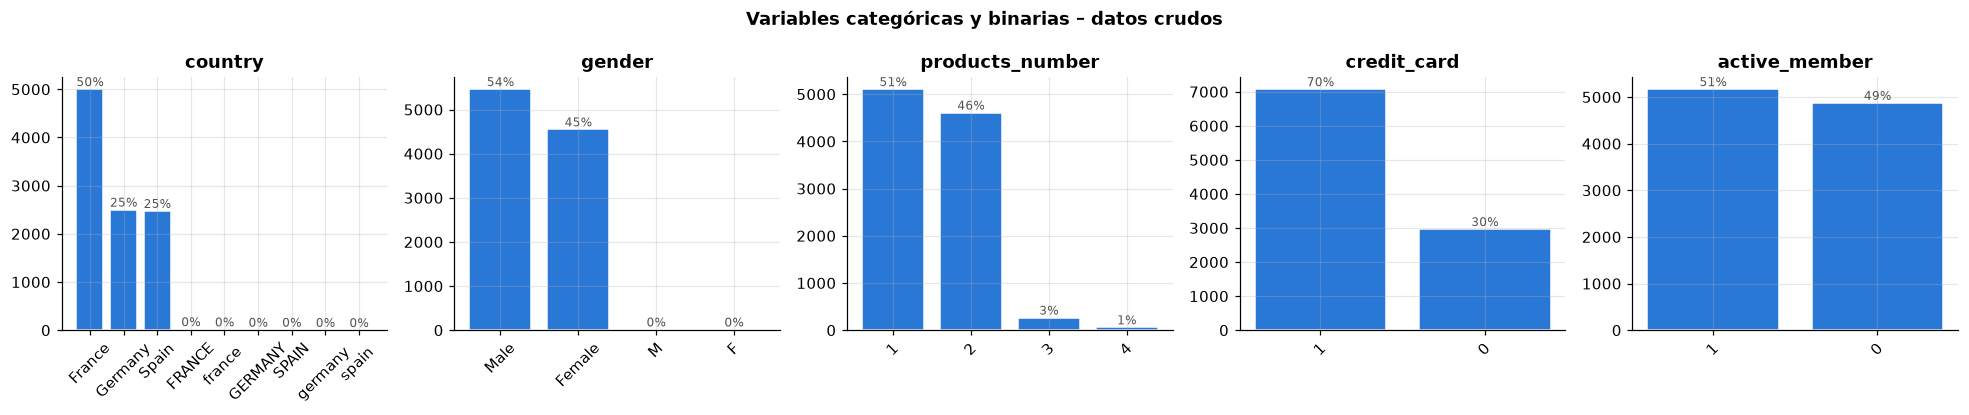

In [6]:
cat_cols = CATEGORICAS + ["products_number"] + BINARIAS
fig, axes = plt.subplots(1, len(cat_cols), figsize=(18, 3.8))
for ax, c in zip(axes, cat_cols):
    vc = df_raw[c].value_counts()
    ax.bar(vc.index.astype(str), vc.values, color=C_NO, edgecolor="white")
    ax.set_title(c); ax.tick_params(axis="x", rotation=45)
    for j, v in enumerate(vc.values):
        ax.text(j, v, f"{v / len(df_raw):.0%}", ha="center", va="bottom", fontsize=8, color="#52514e")
fig.suptitle("Variables categóricas y binarias – datos crudos", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_categoricas_crudas.png", bbox_inches="tight"); plt.show()

**Observaciones**

- `country` y `gender` tienen **categorías escritas de varias formas** (`FRANCE`, `france␣`, `M`, `F`…). Son errores de consistencia, no categorías nuevas.
- Francia concentra cerca de la mitad de los clientes; Alemania y España, una cuarta parte cada uno.
- Hay algo más de hombres (≈ 55 %) que de mujeres.
- `products_number`: el 96 % de los clientes tiene 1 o 2 productos. Las categorías 3 y 4 son minoritarias (≈ 3 % y 0,6 %).
- `credit_card`: el 70 % tiene tarjeta. `active_member` está balanceada (≈ 51 % activos).

### 2.3 Variable objetivo `churn`

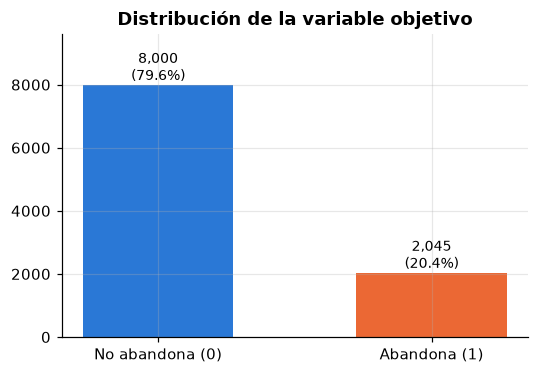

Tasa de abandono: 20.36%  |  razón de desbalance ≈ 3.9 : 1


In [7]:
vc = df_raw[OBJETIVO].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["No abandona (0)", "Abandona (1)"], vc.values, color=[C_NO, C_SI], width=0.55)
for j, v in enumerate(vc.values):
    ax.text(j, v, f"{v:,}\n({v / vc.sum():.1%})", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, vc.max() * 1.2); ax.set_title("Distribución de la variable objetivo")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_objetivo.png", bbox_inches="tight"); plt.show()
print(f"Tasa de abandono: {df_raw[OBJETIVO].mean():.2%}  |  razón de desbalance ≈ {vc[0] / vc[1]:.1f} : 1")

**Desbalance de clases.** Cerca del **20,4 %** de los clientes abandonó el banco (≈ 4 : 1). Esto implica que:

- Un modelo trivial que siempre predice "no abandona" ya obtiene ≈ 80 % de *accuracy*. Por eso la *accuracy* no sirve para elegir modelos: se usarán **F1, precisión, recall, AUC-ROC y AP (área bajo la curva precisión–recall)**.
- Las particiones deben ser **estratificadas** para conservar la proporción de abandono.
- Se evaluará `class_weight="balanced"` como hiperparámetro.
- La tasa del dataset (20,4 %) es mayor que la del mercado de referencia (≈ 15 %). Esta diferencia debe corregirse al calcular el valor económico del modelo.

## 3. Revisión de calidad de datos

Se revisan cuatro dimensiones: **unicidad, completitud, consistencia y validez**.

In [8]:
# Unicidad
print(f"Registros duplicados exactos: {df_raw.duplicated().sum()}")

# Completitud
nulos = pd.DataFrame({"nulos": df_raw.isna().sum(), "% nulos": df_raw.isna().mean() * 100})
display(nulos[nulos.nulos > 0])
print(f"Registros con al menos un nulo: {df_raw.isna().any(axis=1).sum():,} ({df_raw.isna().any(axis=1).mean():.1%})")

Registros duplicados exactos: 45


,nulos,% nulos
credit_score,250,2.4888
age,300,2.9866
balance,200,1.9910
estimated_salary,350,3.4843


Registros con al menos un nulo: 1,100 (11.0%)


In [9]:
# Consistencia: categorías escritas de forma distinta
for c in CATEGORICAS:
    print(c, df_raw[c].value_counts().to_dict())

country {'France': 5003, 'Germany': 2502, 'Spain': 2475, 'FRANCE': 22, 'france ': 17, 'GERMANY': 9, 'SPAIN': 9, 'germany ': 6, 'spain ': 2}
gender {'Male': 5464, 'Female': 4551, 'M': 16, 'F': 14}


In [10]:
# Validez: valores fuera del rango del diccionario
RANGOS = {"credit_score": (300, 850), "age": (18, 100), "tenure": (0, 10),
          "balance": (0, None), "estimated_salary": (0, None),
          "products_number": (1, 4), "credit_card": (0, 1), "active_member": (0, 1), "churn": (0, 1)}

def fuera_de_rango(df):
    filas = []
    for c, (lo, hi) in RANGOS.items():
        s = df[c]
        bajo = (s < lo).sum()
        alto = (s > hi).sum() if hi is not None else 0
        ejemplos = sorted(s[(s < lo) | ((s > hi) if hi is not None else False)].unique().tolist())
        filas.append({"variable": c, "mín válido": lo, "máx válido": hi, "< mín": bajo, "> máx": alto, "valores": ejemplos})
    return pd.DataFrame(filas).set_index("variable")

fuera_de_rango(df_raw)

,mín válido,máx válido,< mín,> máx,valores
variable,,,,,
credit_score,300,850.0000,2,2,"[95.0, 120.0, 999.0, 1200.0]"
age,18,100.0000,3,3,"[-1.0, 0.0, 5.0, 130.0, 150.0, 210.0]"
tenure,0,10.0000,1,2,"[-2, 15, 25]"
balance,0,NaN,0,0,[]
estimated_salary,0,NaN,3,0,"[-5000.0, -120.5, -1.0]"
products_number,1,4.0000,0,0,[]
credit_card,0,1.0000,0,0,[]
active_member,0,1.0000,0,0,[]
churn,0,1.0000,0,0,[]


**Resumen de calidad**

| Dimensión | Hallazgo |
|---|---|
| Unicidad | 45 registros duplicados exactos (0,45 %). |
| Completitud | Nulos en `credit_score` (2,5 %), `age` (3,0 %), `balance` (2,0 %) y `estimated_salary` (3,5 %). Cerca del 11 % de las filas tiene al menos un nulo, así que eliminar filas descartaría demasiada información. |
| Consistencia | `country` con mayúsculas y espacios distintos (`FRANCE`, `france␣`…); `gender` con abreviaturas `M`/`F`. |
| Validez | `age` ∈ {−1, 0, 5, 130, 150, 210}; `credit_score` ∈ {95, 120, 999, 1200}; `tenure` ∈ {−2, 15, 25}; `estimated_salary` negativo en 3 casos. |

## 4. Tratamiento de los datos
### 4.1 Consistencia y duplicados

Primero se unifican las categorías y luego se eliminan los duplicados, para detectar también los que solo difieren en la escritura.

In [11]:
df = df_raw.copy()
df["country"] = df["country"].str.strip().str.title()
df["gender"] = df["gender"].str.strip().replace({"M": "Male", "F": "Female"})
print({c: df[c].value_counts().to_dict() for c in CATEGORICAS})

n0 = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicados eliminados: {n0 - len(df)}  ->  registros restantes: {len(df):,}")

{'country': {'France': 5042, 'Germany': 2517, 'Spain': 2486}, 'gender': {'Male': 5480, 'Female': 4565}}
Duplicados eliminados: 45  ->  registros restantes: 10,000


### 4.2 Valores inválidos: ¿*clipping* o nulo?

La guía del curso sugiere recortar (*clipping*) al rango válido, pero también pide evaluar cuándo conviene marcar el valor como nulo. Aquí **se marcan como nulos** por esta razón:

- Una edad de 210 recortada a 100 crearía un cliente centenario que no existe. Una edad de 0 recortada a 18 crearía un joven que tampoco existe. El error de captura no informa nada sobre el valor real.
- Son muy pocos casos (≤ 6 por variable), así que imputarlos con la mediana del entrenamiento casi no altera la distribución.
- `balance` y `estimated_salary` negativos tampoco tienen interpretación válida y reciben el mismo tratamiento.

In [12]:
n_invalidos = {}
for c, (lo, hi) in RANGOS.items():
    mask = (df[c] < lo) | ((df[c] > hi) if hi is not None else False)
    n_invalidos[c] = int(mask.sum())
    df.loc[mask, c] = np.nan
ENTERAS = ["products_number", "credit_card", "active_member", "churn"]   # sin nulos: se conservan como enteros
df[ENTERAS] = df[ENTERAS].astype(int)
print("Valores inválidos convertidos a NaN:", {k: v for k, v in n_invalidos.items() if v})
fuera_de_rango(df)[["< mín", "> máx"]].T

Valores inválidos convertidos a NaN: {'credit_score': 4, 'age': 6, 'tenure': 3, 'estimated_salary': 3}


variable,credit_score,age,tenure,balance,estimated_salary,products_number,credit_card,active_member,churn
< mín,0,0,0,0,0,0,0,0,0
> máx,0,0,0,0,0,0,0,0,0


### 4.3 Valores atípicos (criterio IQR)

Un valor se considera atípico si está fuera de [Q1 − 1,5·IQR, Q3 + 1,5·IQR].

In [13]:
def resumen_iqr(df, cols):
    filas = []
    for c in cols:
        s = df[c].dropna()
        q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        filas.append({"variable": c, "lím_inf": lo, "lím_sup": hi, "n_atípicos": int(((s < lo) | (s > hi)).sum()),
                      "% atípicos": ((s < lo) | (s > hi)).mean() * 100, "p1": s.quantile(0.01), "p99": s.quantile(0.99),
                      "tasa churn en atípicos": df.loc[s[(s < lo) | (s > hi)].index, OBJETIVO].mean()})
    return pd.DataFrame(filas).set_index("variable")

resumen_iqr(df, CONTINUAS + ["tenure"])

,lím_inf,lím_sup,n_atípicos,% atípicos,p1,p99,tasa churn en atípicos
variable,,,,,,,
credit_score,383.0000,919.0000,12,0.1231,432.0000,850.0000,1.0000
age,14.0000,62.0000,344,3.5486,21.0000,72.0000,0.2006
balance,"-191,305.7325","318,842.8875",0,0.0000,0.0000,"186,103.6479",NaN
estimated_salary,"-96,298.7375","296,781.0425",0,0.0000,"1,798.6164","198,057.6788",NaN
tenure,-3.0000,13.0000,0,0.0000,0.0000,10.0000,NaN


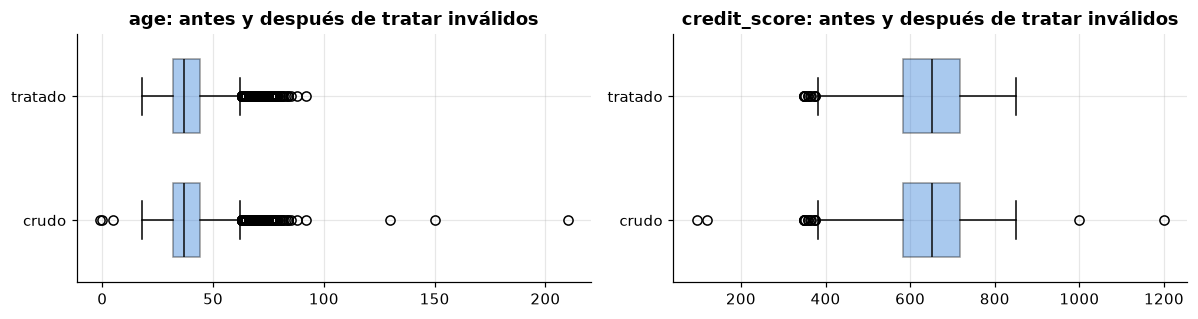

crudo                 tratado             
             age credit_score        age credit_score
count 9,745.0000   9,795.0000 9,694.0000   9,746.0000
mean     38.9376     650.6901    38.9177     650.6241
std      10.7342      97.0880    10.4719      96.6152
min      -1.0000      95.0000    18.0000     350.0000
25%      32.0000     584.0000    32.0000     584.0000
50%      37.0000     652.0000    37.0000     652.0000
75%      44.0000     718.0000    44.0000     718.0000
max     210.0000   1,200.0000    92.0000     850.0000

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, c in zip(axes, ["age", "credit_score"]):
    ax.boxplot([df_raw[c].dropna(), df[c].dropna()], vert=False, widths=0.6, tick_labels=["crudo", "tratado"],
               patch_artist=True, boxprops=dict(facecolor=C_NO, alpha=0.4), medianprops=dict(color="#0b0b0b"))
    ax.set_title(f"{c}: antes y después de tratar inválidos")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_atipicos_antes_despues.png", bbox_inches="tight"); plt.show()
pd.concat({"crudo": df_raw[["age", "credit_score"]].describe(), "tratado": df[["age", "credit_score"]].describe()}, axis=1)

**Decisión sobre los atípicos.** Después de eliminar los valores imposibles, los atípicos que quedan son **valores plausibles**: clientes de 63 a 92 años en `age` y puntajes bajos (350–380) en `credit_score`. **No se recortan**, por tres razones:

1. Son clientes reales y el modelo debe saber puntuarlos en producción.
2. Son informativos. Los 12 clientes con `credit_score` < 383 **abandonaron todos** (100 %). En `age`, los atípicos (> 62 años) tienen en conjunto una tasa similar al promedio (≈ 20 %), pero esconden dos grupos opuestos: 63–70 años (≈ 27 %) y mayores de 70 (≈ 8 %). Recortarlos a 62 borraría justamente esa diferencia.
3. El árbol de decisión es robusto a atípicos. Para la regresión logística, la estandarización y la regularización reducen su efecto.

`balance` y `estimated_salary` no tienen atípicos según el IQR. **La variable objetivo nunca se recorta**: es una etiqueta binaria (0/1) y no tiene valores extremos. Modificarla cambiaría la verdad que se quiere predecir.

### 4.4 Nulos (análisis exploratorio de imputación)

Los nulos están por debajo del 5 % en cada columna. Para ver el efecto de imputar, se compara la media con la mediana. **Esta imputación no se conserva**: la definitiva se hace en el notebook 02, dentro del *pipeline* y ajustada solo con el conjunto de entrenamiento.

                  nulos      %
credit_score        254 2.5400
age                 306 3.0600
tenure                3 0.0300
balance             200 2.0000
estimated_salary    353 3.5300


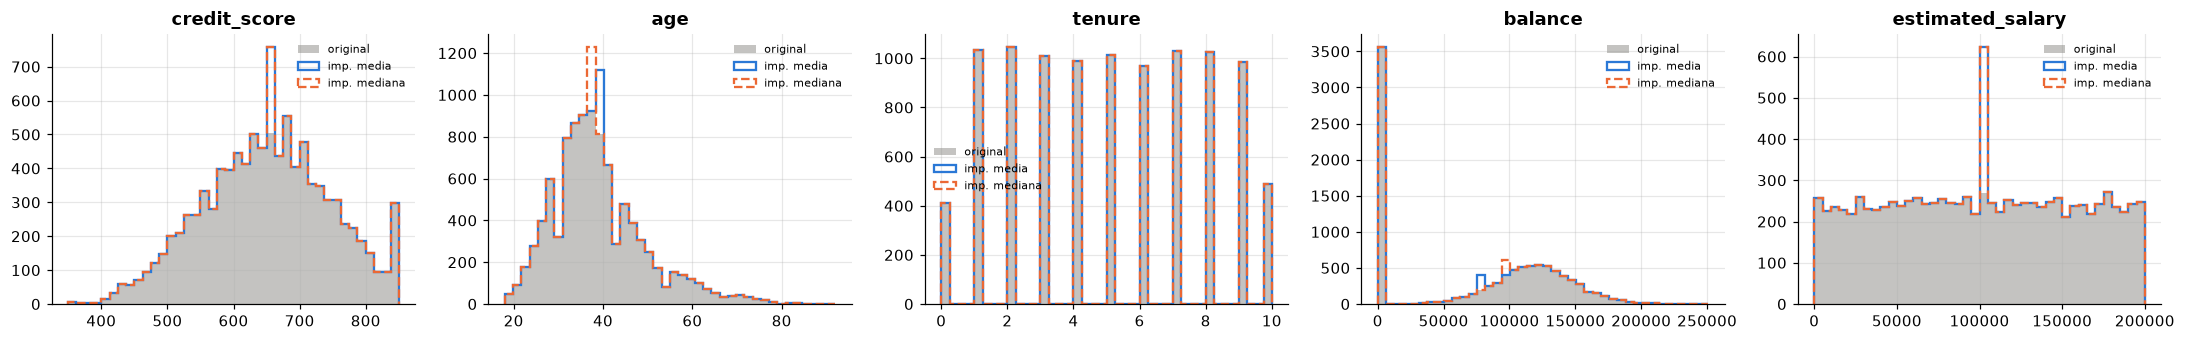

In [15]:
cols_nulos = [c for c in df.columns if df[c].isna().any()]
print(pd.DataFrame({"nulos": df[cols_nulos].isna().sum(), "%": df[cols_nulos].isna().mean() * 100}).round(2))

fig, axes = plt.subplots(1, len(cols_nulos), figsize=(4 * len(cols_nulos), 3.2))
for ax, c in zip(np.atleast_1d(axes), cols_nulos):
    s = df[c]
    ax.hist(s.dropna(), bins=40, color=C_GRIS, alpha=0.5, label="original")
    ax.hist(s.fillna(s.mean()), bins=40, histtype="step", color=C_NO, lw=1.5, label="imp. media")
    ax.hist(s.fillna(s.median()), bins=40, histtype="step", color=C_SI, lw=1.5, ls="--", label="imp. mediana")
    ax.set_title(c); ax.legend(fontsize=7, frameon=False)
plt.tight_layout(); plt.show()

**Conclusión.** Las dos imputaciones solo agregan un pico en un valor central, sin cambiar la forma general. Se elige la **mediana** porque `age` es asimétrica y en `balance` la media (≈ 76.000) cae en una zona poco poblada entre el pico de 0 y la campana de 120.000. Imputar `balance` en 0 sesgaría la variable hacia "sin saldo". Las columnas con nulos se conservan: ninguna supera el 5 %.

## 5. Relación de las variables con el abandono
### 5.1 Variables numéricas según la clase

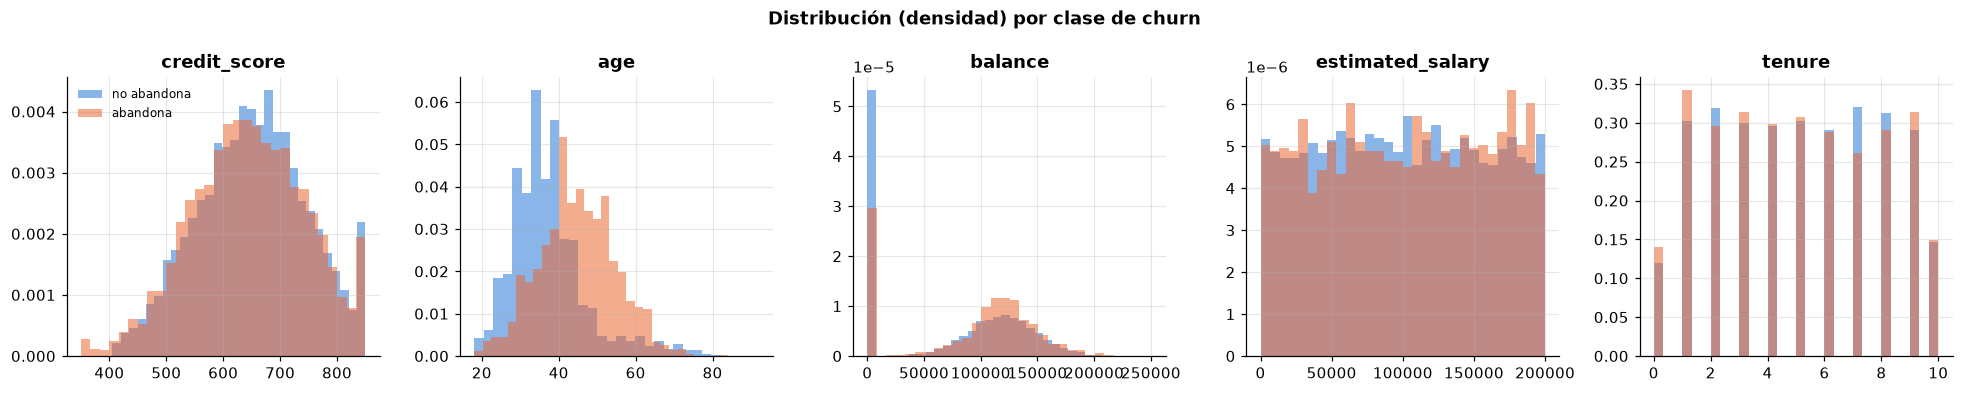

In [16]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
for ax, c in zip(axes, CONTINUAS + ["tenure"]):
    for k, col in PAL_CHURN.items():
        ax.hist(df.loc[df[OBJETIVO] == k, c].dropna(), bins=30, density=True, alpha=0.55, color=col,
                label="abandona" if k else "no abandona")
    ax.set_title(c)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Distribución (densidad) por clase de churn", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_numericas_vs_churn.png", bbox_inches="tight"); plt.show()

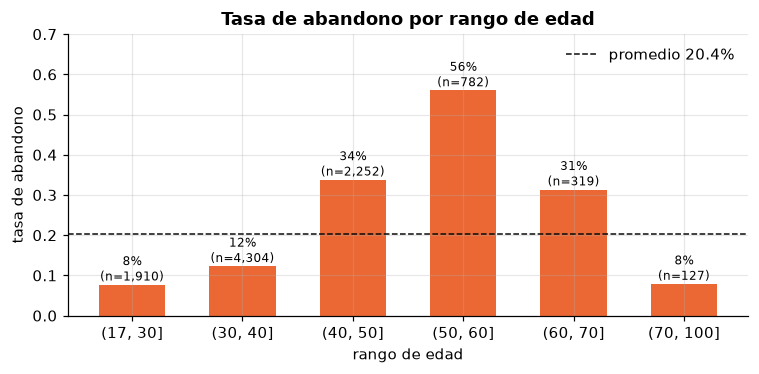

In [17]:
bins = [17, 30, 40, 50, 60, 70, 100]
tasa_edad = df.groupby(pd.cut(df["age"], bins), observed=True)[OBJETIVO].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(tasa_edad.index.astype(str), tasa_edad["mean"], color=C_SI, width=0.6)
ax.axhline(df[OBJETIVO].mean(), color="#0b0b0b", ls="--", lw=1, label=f"promedio {df[OBJETIVO].mean():.1%}")
for j, (m, n) in enumerate(tasa_edad.values):
    ax.text(j, m, f"{m:.0%}\n(n={int(n):,})", ha="center", va="bottom", fontsize=8)
ax.set_ylim(0, 0.7); ax.set_ylabel("tasa de abandono"); ax.set_xlabel("rango de edad"); ax.legend(frameon=False)
ax.set_title("Tasa de abandono por rango de edad")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_churn_por_edad.png", bbox_inches="tight"); plt.show()

**Observaciones**

- **`age` es la variable numérica más discriminante.** Quienes abandonan son ~7 años mayores en promedio. La relación **no es monótona**: la tasa sube de ≈ 8 % (≤ 30 años) a ≈ 56 % (51–60 años) y vuelve a bajar en los mayores de 70. Esta forma de **U invertida** no la captura un término lineal, así que se crea la variable derivada **`age_sq` = edad²** para la regresión logística. El árbol capta la no linealidad por sí solo.
- `balance`: quienes abandonan tienen saldos algo mayores. Entre quienes tienen saldo 0 la tasa es menor (≈ 14 % frente a ≈ 24 %).
- `credit_score`: las distribuciones casi se superponen; la diferencia es muy pequeña.
- `tenure` y `estimated_salary`: las distribuciones son prácticamente iguales en ambas clases.

### 5.2 Tasa de abandono por categoría

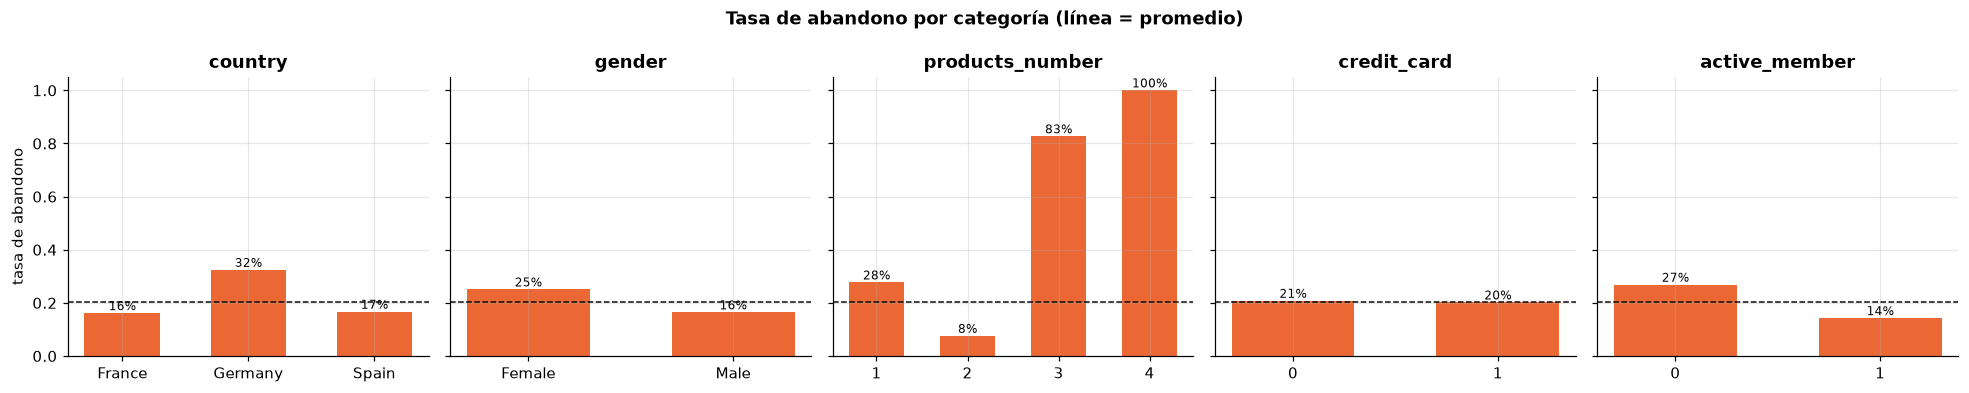

In [18]:
cols = CATEGORICAS + ["products_number"] + BINARIAS
fig, axes = plt.subplots(1, len(cols), figsize=(18, 3.6), sharey=True)
for ax, c in zip(axes, cols):
    t = df.groupby(c)[OBJETIVO].agg(["mean", "size"])
    ax.bar(t.index.astype(str), t["mean"], color=C_SI, width=0.6)
    ax.axhline(df[OBJETIVO].mean(), color="#0b0b0b", ls="--", lw=1)
    for j, (m, n) in enumerate(t.values):
        ax.text(j, m, f"{m:.0%}", ha="center", va="bottom", fontsize=8)
    ax.set_title(c)
axes[0].set_ylabel("tasa de abandono")
fig.suptitle("Tasa de abandono por categoría (línea = promedio)", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_churn_por_categoria.png", bbox_inches="tight"); plt.show()

**Observaciones**

- **Alemania** tiene el doble de abandono (≈ 32 %) que Francia y España (≈ 16–17 %).
- Las **mujeres** abandonan más (≈ 25 %) que los hombres (≈ 16 %).
- **`products_number`** es muy discriminante y **no monótono**: con 2 productos el abandono es mínimo (≈ 8 %), con 1 es del 28 %, y con 3 o 4 es altísimo (83 % y 100 %). Por eso se trata como **categórica** (one-hot) y no como numérica: un coeficiente lineal no puede representar "baja de 1 a 2 y sube de 2 a 4".
- Los **miembros inactivos** abandonan casi el doble (≈ 27 % frente a ≈ 14 %).
- `credit_card` no muestra diferencias (≈ 20 % en ambos grupos).

### 5.3 Pruebas estadísticas

- **Numéricas:** prueba *t* de Welch (medias) y **U de Mann-Whitney** (distribuciones, robusta a asimetría y atípicos). El tamaño del efecto se mide con la *d* de Cohen.
- **Categóricas y binarias:** prueba **χ² de independencia** y **V de Cramér** como medida de fuerza de la asociación.

In [19]:
filas = []
for c in CONTINUAS + ["tenure"]:
    a = df.loc[df[OBJETIVO] == 1, c].dropna(); b = df.loc[df[OBJETIVO] == 0, c].dropna()
    sp = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    filas.append({"variable": c, "media churn=1": a.mean(), "media churn=0": b.mean(),
                  "p t-Welch": stats.ttest_ind(a, b, equal_var=False).pvalue,
                  "p Mann-Whitney": stats.mannwhitneyu(a, b).pvalue, "d de Cohen": (a.mean() - b.mean()) / sp})
pruebas_num = pd.DataFrame(filas).set_index("variable")
pruebas_num["significativa (p<0,05)"] = (pruebas_num[["p t-Welch", "p Mann-Whitney"]] < 0.05).all(axis=1)
pruebas_num.sort_values("p Mann-Whitney")

,media churn=1,media churn=0,p t-Welch,p Mann-Whitney,d de Cohen,"significativa (p<0,05)"
variable,,,,,,
age,44.7657,37.4119,0.0000,0.0000,0.7322,True
balance,"90,774.5603","72,564.2971",0.0000,0.0000,0.2938,True
credit_score,645.3111,651.9761,0.0076,0.0157,-0.0690,True
tenure,4.9327,5.0345,0.1611,0.1570,-0.0352,False
estimated_salary,"101,300.4032","99,754.2554",0.2907,0.2885,0.0269,False


In [20]:
filas = []
for c in CATEGORICAS + ["products_number"] + BINARIAS:
    tabla = pd.crosstab(df[c], df[OBJETIVO])
    chi2, p, dof, _ = stats.chi2_contingency(tabla)
    v = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))
    filas.append({"variable": c, "chi2": chi2, "gl": dof, "p-valor": p, "V de Cramér": v})
pruebas_cat = pd.DataFrame(filas).set_index("variable").sort_values("V de Cramér", ascending=False)
pruebas_cat["significativa (p<0,05)"] = pruebas_cat["p-valor"] < 0.05
pruebas_cat

,chi2,gl,p-valor,V de Cramér,"significativa (p<0,05)"
variable,,,,,
products_number,"1,503.6294",3,0.0000,0.3878,True
country,301.2553,2,0.0000,0.1736,True
active_member,242.9853,1,0.0000,0.1559,True
gender,112.9186,1,0.0000,0.1063,True
credit_card,0.4713,1,0.4924,0.0069,False


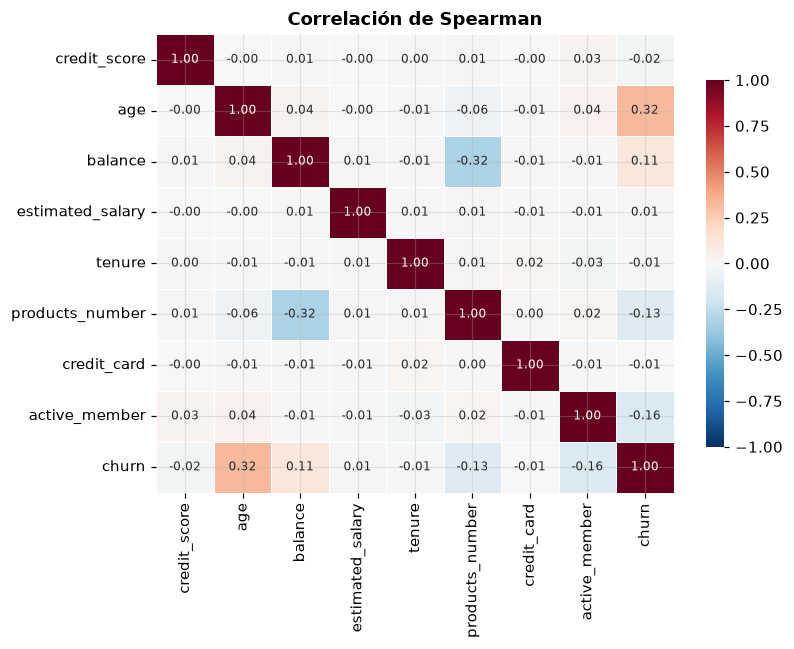

In [21]:
corr = df[CONTINUAS + DISCRETAS + BINARIAS + [OBJETIVO]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax,
            annot_kws={"size": 8}, cbar_kws={"shrink": 0.8}, linewidths=0.5, linecolor="white")
ax.set_title("Correlación de Spearman")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_correlacion.png", bbox_inches="tight"); plt.show()

**Interpretación de las pruebas**

- **Muy significativas y con efecto relevante:** `age` (*d* ≈ 0,7, efecto mediano-grande), `products_number` (V ≈ 0,4, la asociación más fuerte), `country` (V ≈ 0,17), `active_member` (V ≈ 0,16), `gender` (V ≈ 0,11) y `balance` (*d* ≈ 0,3).
- **Significativa pero con efecto muy pequeño:** `credit_score` (*d* ≈ −0,06). Con ~10.000 registros, diferencias mínimas resultan "significativas". Se conserva porque es una variable de negocio natural en un banco y la regularización puede anularla si no aporta.
- **No significativas:** `tenure`, `estimated_salary` y `credit_card` (p > 0,05 en ambas pruebas; V y *d* ≈ 0). Los gráficos confirman que sus distribuciones son iguales en las dos clases.
- **Multicolinealidad:** no hay correlaciones fuertes entre predictores (|ρ| < 0,35). La más notable es `balance`–`products_number` (ρ ≈ −0,32): los clientes con 2 productos suelen tener saldo 0. La correlación de Spearman con `churn` es baja incluso para `age` (ρ ≈ 0,32), porque las relaciones son no monótonas y no se ven en un coeficiente de correlación. Por eso se usan también los gráficos por grupo.

## 6. Selección de variables y exportación

| Decisión | Variables | Justificación |
|---|---|---|
| **Se conservan** | `age`, `products_number`, `country`, `active_member`, `gender`, `balance`, `credit_score` | Diferencias visibles en los gráficos y pruebas significativas. |
| **Derivada** | `age_sq` (edad²) | Captura la U invertida edad–abandono en el modelo lineal. Se calcula dentro del *pipeline* (notebook 02), no aquí. |
| **Se descartan** | `tenure`, `estimated_salary`, `credit_card` | Sin asociación con el abandono (p > 0,05, efecto ≈ 0). Incluirlas agregaría ruido y complejidad sin poder predictivo. |
| **Codificación** | `country`, `gender`, `products_number` → one-hot | `products_number` como categórica por su relación no monótona con el abandono. |

Se exporta el dataset tratado (consistente, sin duplicados ni valores inválidos, **con nulos**), conservando todas las columnas para trazabilidad. La selección de variables se aplica en el notebook 02.

In [22]:
df.to_csv(PROC_DIR / "churn_clean.csv", index=False)
print(f"Guardado: {PROC_DIR / 'churn_clean.csv'}  ->  {df.shape}")
print(f"Tasa de abandono final: {df[OBJETIVO].mean():.2%}")

Guardado: ../data/processed/churn_clean.csv  ->  (10000, 11)
Tasa de abandono final: 20.37%


### Indicadores clave del entendimiento de datos

| Indicador | Valor |
|---|---|
| Registros crudos / tratados | 10.045 / 10.000 |
| Variables | 10 predictoras + 1 objetivo → 7 seleccionadas + 1 derivada |
| Tasa de abandono | 20,4 % (desbalance ≈ 4 : 1) |
| Nulos | 2–3,5 % por columna en 4 variables (se imputarán con la mediana del entrenamiento) |
| Grupo de mayor riesgo | 51–60 años (≈ 56 % de abandono); 3–4 productos (> 80 %); Alemania (≈ 32 %) |